# 🤗 Hugging Face Transformers Mastery — One Notebook to Rule Them All

A single, hands-on path from `pipeline` one-liners to fine-tuning your own transformer. Every
section has a **Concept**, a runnable **Demo**, and an **Exercise** with the solution below.

**The mental model:**
- A **tokenizer** turns text into integer IDs the model understands (and back).
- A **model** maps those IDs to outputs: hidden states, token logits, or class scores.
- A **pipeline** bundles tokenizer + model + pre/post-processing into a one-call API.
- **Fine-tuning** adapts a pretrained model to your task with the `Trainer`.

Everything here uses small, locally-cached models and runs on CPU, so cells finish quickly.

## Table of Contents
1. Setup & the `pipeline` API
2. Tokenizers in depth
3. Loading models with `Auto*` classes
4. Fill-mask with BERT
5. Text generation with GPT-2
6. Hidden states & sentence embeddings
7. Semantic similarity from embeddings
8. The `datasets` library
9. Fine-tuning a classifier with `Trainer`
10. Evaluating & running inference
11. Saving & loading a fine-tuned model
12. 🏆 Capstone — end-to-end text classification

## 1. Setup & the `pipeline` API

`pipeline` is the fastest way to use a model: name a task and a model, and call it on text.
We quiet logging and force CPU so output is clean and reproducible.

In [1]:
import os
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import warnings
warnings.filterwarnings("ignore")

import torch
import transformers
from transformers import pipeline
transformers.logging.set_verbosity_error()

print("transformers:", transformers.__version__)
print("torch       :", torch.__version__)

# A fill-mask pipeline using the locally-cached BERT base model
fill = pipeline("fill-mask", model="bert-base-uncased", device=-1)   # device=-1 -> CPU
for r in fill("The capital of France is [MASK].", top_k=3):
    print(f"{r['token_str']:>10}  score={r['score']:.3f}")

W1101 09:15:21.817000 80719 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


transformers: 5.22.1
torch       : 2.15.0


     paris  score=0.417
     lille  score=0.071
      lyon  score=0.063


**Exercise 1** — Use the same fill-mask pipeline to get the top 3 predictions for `'Paris is a [MASK] city.'`

In [2]:
# Your turn:

In [3]:
# Solution
for r in fill("Paris is a [MASK] city.", top_k=3):
    print(f"{r['token_str']:>12}  {r['score']:.3f}")

     growing  0.093
metropolitan  0.068
cosmopolitan  0.063


## 2. Tokenizers in Depth

The tokenizer is the bridge between text and the model. It splits text into subword tokens,
maps them to integer IDs, adds special tokens (`[CLS]`, `[SEP]`), and builds the attention mask.

In [4]:
from transformers import AutoTokenizer

tok = AutoTokenizer.from_pretrained("bert-base-uncased")

text = "Transformers are powerful!"
enc = tok(text)
print("input_ids     :", enc["input_ids"])
print("tokens        :", tok.convert_ids_to_tokens(enc["input_ids"]))
print("attention_mask:", enc["attention_mask"])
print("decoded       :", tok.decode(enc["input_ids"]))

# Subword splitting: rare words break into pieces (## marks a continuation)
print("\nsubwords:", tok.tokenize("tokenization transformerize"))

# Batch encoding with padding + truncation -> rectangular tensors
batch = tok(["short text", "a somewhat longer piece of text here"],
            padding=True, truncation=True, max_length=16, return_tensors="pt")
print("\nbatch input_ids shape:", batch["input_ids"].shape)
print(batch["input_ids"])

input_ids     : [101, 19081, 2024, 3928, 999, 102]
tokens        : ['[CLS]', 'transformers', 'are', 'powerful', '!', '[SEP]']
attention_mask: [1, 1, 1, 1, 1, 1]
decoded       : [CLS] transformers are powerful! [SEP]

subwords: ['token', '##ization', 'transform', '##eri', '##ze']

batch input_ids shape: torch.Size([2, 9])
tensor([[ 101, 2460, 3793,  102,    0,    0,    0,    0,    0],
        [ 101, 1037, 5399, 2936, 3538, 1997, 3793, 2182,  102]])


**Exercise 2** — Tokenize `'Hugging Face'` with the BERT tokenizer and print how many tokens it becomes (excluding the special `[CLS]`/`[SEP]`).

In [5]:
# Your turn:

In [6]:
# Solution
pieces = tok.tokenize("Hugging Face")
print("tokens:", pieces, "-> count:", len(pieces))

tokens: ['hugging', 'face'] -> count: 2


## 3. Loading Models with `Auto*` Classes

The `Auto*` classes pick the right architecture from a model's name. Choose the head for your
task: `AutoModel` (raw hidden states), `AutoModelForMaskedLM`, `AutoModelForCausalLM`,
`AutoModelForSequenceClassification`, etc.

In [7]:
from transformers import AutoModel, AutoConfig

config = AutoConfig.from_pretrained("distilbert-base-uncased")
print("hidden size :", config.dim)
print("num layers  :", config.n_layers)
print("vocab size  :", config.vocab_size)

model = AutoModel.from_pretrained("distilbert-base-uncased")
model.eval()
n_params = sum(p.numel() for p in model.parameters())
print(f"parameters  : {n_params:,}")

tok = AutoTokenizer.from_pretrained("distilbert-base-uncased")
inputs = tok("Hello world", return_tensors="pt")
with torch.no_grad():
    out = model(**inputs)
print("last_hidden_state shape:", out.last_hidden_state.shape)   # (batch, seq_len, hidden)

hidden size : 768
num layers  : 6
vocab size  : 30522


parameters  : 66,362,880


last_hidden_state shape: torch.Size([1, 4, 768])


**Exercise 3** — Load the config for `bert-base-uncased` and print its number of hidden layers and attention heads (`num_hidden_layers`, `num_attention_heads`).

In [8]:
# Your turn:

In [9]:
# Solution
cfg = AutoConfig.from_pretrained("bert-base-uncased")
print("layers:", cfg.num_hidden_layers, "| heads:", cfg.num_attention_heads)

layers: 12 | heads: 12


## 4. Fill-Mask with BERT

BERT is trained to predict masked tokens. This "masked language modeling" objective is what
makes its representations useful. Let's call the model directly rather than via a pipeline.

In [10]:
from transformers import AutoModelForMaskedLM

tok = AutoTokenizer.from_pretrained("bert-base-uncased")
mlm = AutoModelForMaskedLM.from_pretrained("bert-base-uncased")
mlm.eval()

text = "The weather today is very [MASK]."
inputs = tok(text, return_tensors="pt")
mask_pos = (inputs["input_ids"] == tok.mask_token_id)[0].nonzero(as_tuple=True)[0]

with torch.no_grad():
    logits = mlm(**inputs).logits

top5 = logits[0, mask_pos].topk(5, dim=-1).indices[0]
print("predictions for [MASK]:")
for tid in top5:
    print("  ", tok.decode(tid))

predictions for [MASK]:
   warm
   good
   hot
   pleasant
   cold


**Exercise 4** — Find BERT's top prediction for the mask in `'I love programming in [MASK].'`

In [11]:
# Your turn:

In [12]:
# Solution
inputs = tok("I love programming in [MASK].", return_tensors="pt")
pos = (inputs["input_ids"] == tok.mask_token_id)[0].nonzero(as_tuple=True)[0]
with torch.no_grad():
    logits = mlm(**inputs).logits
print("top prediction:", tok.decode(logits[0, pos].argmax(-1)))

top prediction: general


## 5. Text Generation with GPT-2

GPT-2 is an autoregressive (causal) model: it predicts the next token given all previous ones.
Generation walks that forward one token at a time. We use greedy decoding for reproducibility.

In [13]:
from transformers import AutoModelForCausalLM

tok = AutoTokenizer.from_pretrained("gpt2")
gpt = AutoModelForCausalLM.from_pretrained("gpt2")
gpt.eval()

prompt = "Machine learning is"
inputs = tok(prompt, return_tensors="pt")
with torch.no_grad():
    out = gpt.generate(**inputs, max_new_tokens=30, do_sample=False,
                       pad_token_id=tok.eos_token_id)
print(tok.decode(out[0], skip_special_tokens=True))

Machine learning is a very powerful tool for learning about the world around us. It's a tool that can help us understand the world around us, and it's a


In [14]:
# Sampling with temperature produces more varied text
torch.manual_seed(0)
with torch.no_grad():
    out = gpt.generate(**inputs, max_new_tokens=30, do_sample=True,
                       temperature=0.8, top_k=50, pad_token_id=tok.eos_token_id)
print("sampled:\n", tok.decode(out[0], skip_special_tokens=True))

sampled:
 Machine learning is a fundamental part of our business and is crucial for us to continue executing on the roadmap and to make sure we have the best possible customer experience for our


**Exercise 5** — Generate a 20-token greedy continuation of the prompt `'The best way to learn is'` with GPT-2.

In [15]:
# Your turn:

In [16]:
# Solution
inp = tok("The best way to learn is", return_tensors="pt")
with torch.no_grad():
    out = gpt.generate(**inp, max_new_tokens=20, do_sample=False, pad_token_id=tok.eos_token_id)
print(tok.decode(out[0], skip_special_tokens=True))

The best way to learn is to go to the library and read the book.

The best way to learn is to go


## 6. Hidden States & Sentence Embeddings

A transformer turns each token into a context-aware vector. To get one vector for a whole
sentence, **mean-pool** the token vectors (weighted by the attention mask). These embeddings
capture meaning and power search, clustering, and similarity.

In [17]:
tok = AutoTokenizer.from_pretrained("distilbert-base-uncased")
model = AutoModel.from_pretrained("distilbert-base-uncased")
model.eval()

def embed(sentences):
    enc = tok(sentences, padding=True, truncation=True, return_tensors="pt")
    with torch.no_grad():
        out = model(**enc).last_hidden_state          # (B, T, H)
    mask = enc["attention_mask"].unsqueeze(-1).float() # (B, T, 1)
    summed = (out * mask).sum(dim=1)
    counts = mask.sum(dim=1).clamp(min=1e-9)
    return summed / counts                             # mean-pooled (B, H)

vecs = embed(["I love cats.", "Dogs are great pets.", "The stock market fell today."])
print("embedding matrix shape:", vecs.shape)   # (3, 768)

embedding matrix shape: torch.Size([3, 768])


**Exercise 6** — Embed the single sentence `'Natural language processing is fun.'` and print the length of its embedding vector.

In [18]:
# Your turn:

In [19]:
# Solution
v = embed(["Natural language processing is fun."])
print("embedding dim:", v.shape[1])

embedding dim: 768


## 7. Semantic Similarity from Embeddings

Cosine similarity between sentence embeddings measures how related two sentences are —
regardless of exact wording. This is the core of semantic search.

In [20]:
import torch.nn.functional as F

sentences = [
    "The cat sat on the mat.",
    "A feline rested on the rug.",      # similar meaning to #0
    "Quarterly earnings beat expectations.",
]
vecs = embed(sentences)
vecs = F.normalize(vecs, dim=1)
sim = vecs @ vecs.T                      # cosine similarity matrix

print("similarity matrix:")
for i in range(len(sentences)):
    print("  ", [f"{sim[i, j]:.2f}" for j in range(len(sentences))])
print(f"\nsim(cat/mat, feline/rug) = {sim[0,1]:.3f}  (high -> similar)")
print(f"sim(cat/mat, earnings)   = {sim[0,2]:.3f}  (low  -> unrelated)")

similarity matrix:
   ['1.00', '0.89', '0.62']
   ['0.89', '1.00', '0.64']
   ['0.62', '0.64', '1.00']

sim(cat/mat, feline/rug) = 0.892  (high -> similar)
sim(cat/mat, earnings)   = 0.623  (low  -> unrelated)


**Exercise 7** — Given a query `'How do I cook pasta?'` and two candidates (`'Boil water and add noodles.'`, `'The weather is sunny.'`), print which candidate is more similar.

In [21]:
# Your turn:

In [22]:
# Solution
q = F.normalize(embed(["How do I cook pasta?"]), dim=1)
cands = ["Boil water and add noodles.", "The weather is sunny."]
c = F.normalize(embed(cands), dim=1)
sims = (q @ c.T)[0]
print("similarities:", [f"{s:.3f}" for s in sims])
print("most similar:", cands[int(sims.argmax())])

similarities: ['0.750', '0.662']
most similar: Boil water and add noodles.


## 8. The `datasets` Library

`datasets` loads and processes data efficiently (memory-mapped, batched `map`). We use the
locally-cached **rotten_tomatoes** movie-review dataset (binary sentiment).

In [23]:
from datasets import load_dataset

ds = load_dataset("rotten_tomatoes")
print(ds)
print("\nexample:", ds["train"][0])
print("label names:", ds["train"].features["label"].names)   # ['neg', 'pos']

# Tokenize the whole split with a batched map
tok = AutoTokenizer.from_pretrained("distilbert-base-uncased")
def tokenize(batch):
    return tok(batch["text"], truncation=True, padding="max_length", max_length=64)

small = ds["train"].shuffle(seed=0).select(range(400))
tokenized = small.map(tokenize, batched=True)
print("\ntokenized columns:", tokenized.column_names)

Using the latest cached version of the dataset since rotten_tomatoes couldn't be found on the Hugging Face Hub


Found the latest cached dataset configuration 'default' at /Users/I590236/.cache/huggingface/datasets/rotten_tomatoes/default/0.0.0/aa13bc287fa6fcab6daf52f0dfb9994269ffea28 (last modified on Sun Nov  1 09:05:16 2026).


DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 8530
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 1066
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 1066
    })
})

example: {'text': 'the rock is destined to be the 21st century\'s new " conan " and that he\'s going to make a splash even greater than arnold schwarzenegger , jean-claud van damme or steven segal .', 'label': 1}
label names: ['neg', 'pos']



tokenized columns: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask']


**Exercise 8** — From the rotten_tomatoes train split, count how many of the first 100 examples are positive (label 1).

In [24]:
# Your turn:

In [25]:
# Solution
labels = ds["train"]["label"][:100]
print("positives in first 100:", sum(labels))

positives in first 100: 100


## 9. Fine-Tuning a Classifier with `Trainer`

Fine-tuning adapts a pretrained model to your task by adding a classification head and training
on labeled examples. `Trainer` handles the training loop, batching, and optimization.

We fine-tune the compact **DistilBERT** model on a small slice of rotten_tomatoes — small enough to
finish quickly on CPU, while showing the exact real-world workflow.

In [26]:
from transformers import AutoModelForSequenceClassification, Trainer, TrainingArguments
import numpy as np

tok = AutoTokenizer.from_pretrained("distilbert-base-uncased")
def tokenize(batch):
    return tok(batch["text"], truncation=True, padding="max_length", max_length=64)

train_ds = ds["train"].shuffle(seed=0).select(range(500)).map(tokenize, batched=True)
eval_ds  = ds["test"].shuffle(seed=0).select(range(200)).map(tokenize, batched=True)
cols = ["input_ids", "attention_mask", "label"]
train_ds.set_format("torch", columns=cols)
eval_ds.set_format("torch", columns=cols)

model = AutoModelForSequenceClassification.from_pretrained("distilbert-base-uncased", num_labels=2)

args = TrainingArguments(
    output_dir="/tmp/distilbert_rt",
    num_train_epochs=2,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    learning_rate=5e-5,
    logging_steps=10,
    report_to="none",
    use_cpu=True,              # force CPU for a clean, reproducible run
    disable_tqdm=True,
)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {"accuracy": (preds == labels).mean()}

trainer = Trainer(model=model, args=args,
                  train_dataset=train_ds, eval_dataset=eval_ds,
                  compute_metrics=compute_metrics)
trainer.train()
print("\nfine-tuning complete")

{'loss': '0.7017', 'grad_norm': '1.755', 'learning_rate': '4.297e-05', 'epoch': '0.3125'}


{'loss': '0.6783', 'grad_norm': '3.505', 'learning_rate': '3.516e-05', 'epoch': '0.625'}


{'loss': '0.6061', 'grad_norm': '2.223', 'learning_rate': '2.734e-05', 'epoch': '0.9375'}


{'loss': '0.458', 'grad_norm': '2.734', 'learning_rate': '1.953e-05', 'epoch': '1.25'}


{'loss': '0.4089', 'grad_norm': '3.137', 'learning_rate': '1.172e-05', 'epoch': '1.562'}


{'loss': '0.2788', 'grad_norm': '3.416', 'learning_rate': '3.906e-06', 'epoch': '1.875'}


{'train_runtime': '23.97', 'train_samples_per_second': '41.71', 'train_steps_per_second': '2.67', 'train_loss': '0.5148', 'epoch': '2'}

fine-tuning complete


**Exercise 9** — Print the number of trainable parameters in the fine-tuned DistilBERT classifier.

In [27]:
# Your turn:

In [28]:
# Solution
print("params:", sum(p.numel() for p in model.parameters() if p.requires_grad))

params: 66955010


## 10. Evaluating & Running Inference

Evaluate on the held-out set, then run the fine-tuned model on fresh text.

In [29]:
metrics = trainer.evaluate()
print("eval accuracy:", round(metrics["eval_accuracy"], 3))

# Inference on new reviews
model.eval()
reviews = ["An absolute masterpiece, I loved every minute.",
           "Boring, predictable, and a total waste of time."]
enc = tok(reviews, padding=True, truncation=True, max_length=64, return_tensors="pt")
with torch.no_grad():
    probs = torch.softmax(model(**enc).logits, dim=-1)
names = ds["train"].features["label"].names
for review, p in zip(reviews, probs):
    cls = p.argmax().item()
    print(f"[{names[cls]}  {p[cls]:.2f}]  {review}")

{'eval_loss': '0.4435', 'eval_accuracy': '0.805', 'eval_runtime': '1.138', 'eval_samples_per_second': '175.7', 'eval_steps_per_second': '3.515', 'epoch': '2'}
eval accuracy: 0.805
[pos  0.90]  An absolute masterpiece, I loved every minute.
[neg  0.87]  Boring, predictable, and a total waste of time.


**Exercise 10** — Classify the review `'It was okay, nothing special.'` with the fine-tuned model and print the predicted label and its probability.

In [30]:
# Your turn:

In [31]:
# Solution
enc = tok(["It was okay, nothing special."], return_tensors="pt", truncation=True, max_length=64)
with torch.no_grad():
    p = torch.softmax(model(**enc).logits, dim=-1)[0]
print(f"{names[p.argmax().item()]}  ({p.max().item():.2f})")

neg  (0.80)


## 11. Saving & Loading a Fine-Tuned Model

`save_pretrained` writes the model + config; save the tokenizer alongside it. Reload both with
`from_pretrained` and pointing at the directory — or wrap them in a `pipeline`.

In [32]:
import tempfile, os
save_dir = os.path.join(tempfile.mkdtemp(), "my_sentiment_model")

model.save_pretrained(save_dir)
tok.save_pretrained(save_dir)
print("saved files:", sorted(os.listdir(save_dir)))

# Reload as a ready-to-use pipeline
clf = pipeline("text-classification", model=save_dir, tokenizer=save_dir, device=-1)
print(clf("What a fantastic film!"))
print(clf("I regret watching this."))

saved files: ['config.json', 'model.safetensors', 'tokenizer.json', 'tokenizer_config.json']


[{'label': 'LABEL_1', 'score': 0.8355749249458313}]
[{'label': 'LABEL_0', 'score': 0.5830457210540771}]


**Exercise 11** — Reload the saved model into a `text-classification` pipeline and classify `'A thrilling and emotional ride.'`

In [33]:
# Your turn:

In [34]:
# Solution
clf2 = pipeline("text-classification", model=save_dir, tokenizer=save_dir, device=-1)
print(clf2("A thrilling and emotional ride."))

[{'label': 'LABEL_1', 'score': 0.9260647892951965}]


## 12. 🏆 Capstone — End-to-End Text Classification

Put the whole workflow together. Try before peeking.

**Task.** (1) Load a fresh slice of rotten_tomatoes; (2) tokenize it; (3) fine-tune DistilBERT
for 2 epochs; (4) report evaluation accuracy; (5) build a confusion matrix of predictions on
the eval set; (6) classify three of your own sentences.

In [35]:
# Your turn:

{'loss': '0.6942', 'grad_norm': '1.018', 'learning_rate': '3.516e-05', 'epoch': '0.625'}


{'loss': '0.5412', 'grad_norm': '3.385', 'learning_rate': '1.953e-05', 'epoch': '1.25'}


{'loss': '0.393', 'grad_norm': '3.943', 'learning_rate': '3.906e-06', 'epoch': '1.875'}


{'train_runtime': '24.99', 'train_samples_per_second': '40.01', 'train_steps_per_second': '2.561', 'train_loss': '0.5294', 'epoch': '2'}


{'eval_loss': '0.4495', 'eval_accuracy': '0.8', 'eval_runtime': '1.46', 'eval_samples_per_second': '137', 'eval_steps_per_second': '17.13', 'epoch': '2'}
eval accuracy: 0.8


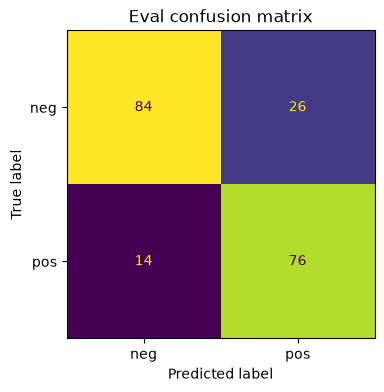

[pos 0.90] A dazzling, unforgettable experience.
[neg 0.86] Dull and far too long.
[neg 0.58] Not perfect, but genuinely enjoyable.


In [36]:
# Solution
from transformers import AutoModelForSequenceClassification, Trainer, TrainingArguments
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np, matplotlib.pyplot as plt, torch

tok = AutoTokenizer.from_pretrained("distilbert-base-uncased")
def tk(b): return tok(b["text"], truncation=True, padding="max_length", max_length=64)

tr = ds["train"].shuffle(seed=1).select(range(500)).map(tk, batched=True)
ev = ds["test"].shuffle(seed=1).select(range(200)).map(tk, batched=True)
cols = ["input_ids", "attention_mask", "label"]
tr.set_format("torch", columns=cols); ev.set_format("torch", columns=cols)

model = AutoModelForSequenceClassification.from_pretrained("distilbert-base-uncased", num_labels=2)
args = TrainingArguments(output_dir="/tmp/cap_rt", num_train_epochs=2,
                         per_device_train_batch_size=16, learning_rate=5e-5,
                         report_to="none", use_cpu=True, disable_tqdm=True, logging_steps=20)
def metrics(p):
    return {"accuracy": (np.argmax(p[0], -1) == p[1]).mean()}
trainer = Trainer(model=model, args=args, train_dataset=tr, eval_dataset=ev,
                  compute_metrics=metrics)
trainer.train()
print("eval accuracy:", round(trainer.evaluate()["eval_accuracy"], 3))

# Confusion matrix on the eval set
pred = np.argmax(trainer.predict(ev).predictions, axis=-1)
true = np.array(ev["label"])
names = ds["train"].features["label"].names
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(confusion_matrix(true, pred), display_labels=names).plot(ax=ax, colorbar=False)
ax.set_title("Eval confusion matrix")
plt.show()

# Classify custom sentences
model.eval()
mine = ["A dazzling, unforgettable experience.",
        "Dull and far too long.",
        "Not perfect, but genuinely enjoyable."]
enc = tok(mine, padding=True, truncation=True, max_length=64, return_tensors="pt")
with torch.no_grad():
    probs = torch.softmax(model(**enc).logits, dim=-1)
for s, p in zip(mine, probs):
    print(f"[{names[p.argmax().item()]} {p.max().item():.2f}] {s}")

---
## 🎓 You Made It

If you can tokenize text, call a model, and run a `Trainer` fine-tune, you have the core of
modern NLP. Where to go next:

- Swap in a full dataset and more epochs for stronger accuracy.
- Explore more tasks: `pipeline("ner")`, `pipeline("question-answering")`,
  `pipeline("summarization")`, `pipeline("zero-shot-classification")`.
- Learn `sentence-transformers` for production-grade embeddings and semantic search.
- Study parameter-efficient fine-tuning (LoRA via the `peft` library) for large models.

Delete the solution cells and redo the exercises in a week — spaced repetition turns practice
into mastery.

> **Note on models/data:** this notebook uses locally-cached models (`bert-base-uncased`,
> `distilbert-base-uncased`, `gpt2`) and the `rotten_tomatoes` dataset.
> The first run of any *new* model or dataset downloads it from the Hugging Face Hub, which
> needs an internet connection.